<a href="https://colab.research.google.com/github/AnnMarie1312/seminarski-rac-vid/blob/main/XAI_Rendgenske_snimke_POBOLJSANO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objašnjivost dubokih modela u klasifikaciji medicinskih slika
**Kolegij:** Računalni vid  
**Model:** ResNet18 (transfer learning)  
**Metode:** Grad-CAM, Grad-CAM++, Integrated Gradients  
**Zadatak:** Klasifikacija rendgenskih snimki pluća: NORMAL / PNEUMONIA

> Istraživački/obrazovni eksperiment, nije medicinski dijagnostički alat. Prvo uključite GPU: Runtime → Change runtime type → T4 GPU. Izvršavajte ćelije redom. Datoteke rezultata spremaju se u `/content/xai_rezultati`.

**Nadograđena verzija:** analiza pogrešaka po klasama, pragovi na validacijskom skupu, reprezentativniji XAI primjeri, predznačene Integrated Gradients atribucije i metapodaci eksperimenta. Izvorni prag 0,5 ostaje za usporedivost; alternativni pragovi su samo analiza. **Ponovno izvršavanje ćelija stvara nove izlaze; postojeći trenirani model se ne mijenja.**


In [1]:
!pip -q install kagglehub grad-cam captum scikit-learn seaborn pandas pillow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Uvoz, konfiguracija i ponovljivost

In [2]:
import os, random, json, copy, shutil, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, classification_report, roc_curve)
from tqdm.auto import tqdm
import kagglehub
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
from google.colab import drive
drive.mount('/content/drive')
OUT=Path('/content/drive/MyDrive/XAI_Rendgenske_snimke'); OUT.mkdir(parents=True, exist_ok=True)
print('Trajna mapa rezultata:', OUT)
BATCH_SIZE=32; EPOCHS=5; LR=1e-4; SIZE=224
print('Uređaj:',device)

Mounted at /content/drive
Trajna mapa rezultata: /content/drive/MyDrive/XAI_Rendgenske_snimke
Uređaj: cuda


## 2. Podaci i podjela
Javno dostupan skup **Chest X-Ray Images (Pneumonia)** (Kermany i sur.). KaggleHub preuzima javnu kopiju; ako preuzimanje ne uspije, ručno preuzmite skup i promijenite `DATA_ROOT`. Originalni testni skup ostaje netaknut. Iz originalnog trening skupa izdvajamo stratificirani validacijski podskup od 15 %. Izvorni `val` direktorij ne koristimo jer je premalen. **Ograničenje:** neovisnost na razini pacijenta nije provjerena, a snimke i oznake mogu sadržavati pristranosti.

In [3]:
dataset_path=Path(kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia'))
print('Preuzeto:',dataset_path)
candidates=[x for x in [dataset_path, *dataset_path.rglob('chest_xray')] if (x/'train'/'NORMAL').exists() and (x/'test'/'PNEUMONIA').exists()]
assert candidates, 'Nije pronađena očekivana struktura train/NORMAL i test/PNEUMONIA.'
DATA_ROOT=candidates[0]
CLASSES=['NORMAL','PNEUMONIA']; class_to_idx={c:i for i,c in enumerate(CLASSES)}
def files_for(split):
    return [(str(f),class_to_idx[c]) for c in CLASSES for f in sorted((DATA_ROOT/split/c).glob('*')) if f.suffix.lower() in ('.jpg','.jpeg','.png')]
train_all=files_for('train'); test_items=files_for('test')
train_items,val_items=train_test_split(train_all,test_size=0.15,random_state=SEED,stratify=[y for _,y in train_all])
for name,items in [('train',train_items),('val',val_items),('test',test_items)]:
 print(name,len(items),pd.Series([CLASSES[y] for _,y in items]).value_counts().to_dict())
assert len(train_items)>0 and len(test_items)>0
# Provjera da ista datoteka nije istodobno u više skupova.
paths_by_split={k:{str(Path(p).resolve()) for p,_ in v} for k,v in [('train',train_items),('val',val_items),('test',test_items)]}
assert not (paths_by_split['train'] & paths_by_split['val'])
assert not (paths_by_split['train'] & paths_by_split['test'])
assert not (paths_by_split['val'] & paths_by_split['test'])
print('Nema preklapanja putanja između podskupova. Neovisnost pacijenata nije provjerena.')


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Preuzeto: /kaggle/input/chest-xray-pneumonia
train 4433 {'PNEUMONIA': 3293, 'NORMAL': 1140}
val 783 {'PNEUMONIA': 582, 'NORMAL': 201}
test 624 {'PNEUMONIA': 390, 'NORMAL': 234}
Nema preklapanja putanja između podskupova. Neovisnost pacijenata nije provjerena.


## 3. Transformacije i DataLoader

In [4]:
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
train_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.RandomRotation(5),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
eval_tf=transforms.Compose([transforms.Resize((SIZE,SIZE)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
class XrayDataset(Dataset):
 def __init__(self,items,transform): self.items=items;self.transform=transform
 def __len__(self): return len(self.items)
 def __getitem__(self,i):
  path,y=self.items[i]
  with Image.open(path) as im: im=im.convert('RGB'); x=self.transform(im)
  return x,y
loaders={name:DataLoader(XrayDataset(items,train_tf if name=='train' else eval_tf),batch_size=BATCH_SIZE,shuffle=name=='train',num_workers=2,pin_memory=torch.cuda.is_available()) for name,items in [('train',train_items),('val',val_items),('test',test_items)]}

## 4. ResNet18 – transfer learning i treniranje
Ako postoji `resnet18_best.pt`, treniranje se preskače. Tijekom prvog treniranja stanje se sprema nakon svake epohe u `resnet18_progress.pt`.


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


NAPOMENA: stariji model nema metapodatke; identitet podjele nije moguće retroaktivno potvrditi.
Pronađen spremljeni model: preskačem treniranje.


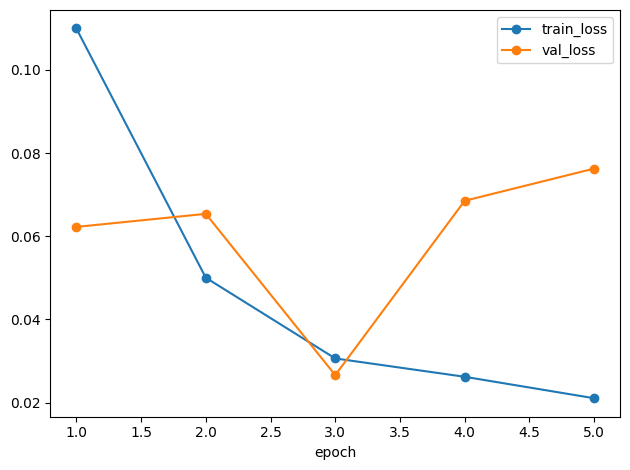

In [5]:
weights=models.ResNet18_Weights.DEFAULT
model=models.resnet18(weights=weights)
model.fc=nn.Linear(model.fc.in_features,2)
model=model.to(device)
counts=np.bincount([y for _,y in train_items],minlength=2)
class_weights=torch.tensor(len(train_items)/(2*counts),dtype=torch.float32,device=device)
criterion=nn.CrossEntropyLoss(weight=class_weights)
optimizer=torch.optim.Adam(model.parameters(),lr=LR)
# Spremljeni najbolji model preskače ponovno treniranje nakon prekida Colab sesije.
# Identifikator podjele i postavki služi za dokumentiranje eksperimenta.
def split_fingerprint(items):
    entries=[f'{Path(path).relative_to(DATA_ROOT)}:{label}' for path,label in items]
    return hashlib.sha256('\n'.join(sorted(entries)).encode()).hexdigest()
experiment_info={'dataset':'paultimothymooney/chest-xray-pneumonia',
                 'seed':SEED,'size':SIZE,'epochs':EPOCHS,'lr':LR,'batch_size':BATCH_SIZE,
                 'classes':CLASSES,'train_split_sha256':split_fingerprint(train_items),
                 'val_split_sha256':split_fingerprint(val_items),
                 'test_split_sha256':split_fingerprint(test_items)}
(OUT/'postavke_eksperimenta.json').write_text(json.dumps(experiment_info,indent=2,ensure_ascii=False),encoding='utf-8')
checkpoint_path = OUT / 'resnet18_best.pt'
progress_path = OUT / 'resnet18_progress.pt'
history = []
best_val = float('inf')
best_state = None
start_epoch = 0

if checkpoint_path.is_file():
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    assert checkpoint['classes'] == CLASSES and checkpoint['size'] == SIZE, 'Spremljeni model ne odgovara postavkama.'
    model.load_state_dict(checkpoint['state_dict'], strict=True)
    if 'experiment_info' in checkpoint and checkpoint['experiment_info'] != experiment_info:
        raise ValueError('Spremljeni model ima različite postavke ili podjelu podataka.')
    if 'experiment_info' not in checkpoint:
        print('NAPOMENA: stariji model nema metapodatke; identitet podjele nije moguće retroaktivno potvrditi.')
    print('Pronađen spremljeni model: preskačem treniranje.')
else:
    if progress_path.is_file():
        progress = torch.load(progress_path, map_location=device, weights_only=False)
        assert progress['classes'] == CLASSES and progress['size'] == SIZE and progress['epochs'] == EPOCHS, 'Postavke nastavka treniranja se razlikuju.'
        model.load_state_dict(progress['current_state'])
        optimizer.load_state_dict(progress['optimizer_state'])
        history = progress['history']
        best_val = progress['best_val']
        best_state = progress['best_state']
        start_epoch = progress['completed_epochs']
        print(f'Nastavljam treniranje od epohe {start_epoch+1}/{EPOCHS}.')
    for epoch in range(start_epoch, EPOCHS):
        row={'epoch':epoch+1}
        for phase in ('train','val'):
            model.train(phase=='train'); losses=[]; correct=total=0
            for x,y in tqdm(loaders[phase],desc=f'Epoha {epoch+1}/{EPOCHS} {phase}',leave=False):
                x=x.to(device);y=y.to(device)
                optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase=='train'):
                    logits=model(x); loss=criterion(logits,y)
                    if phase=='train':loss.backward();optimizer.step()
                losses.append(loss.item()*len(y));correct+=(logits.argmax(1)==y).sum().item();total+=len(y)
            row[f'{phase}_loss']=sum(losses)/total;row[f'{phase}_accuracy']=correct/total
        history.append(row);print(row)
        if row['val_loss']<best_val:
            best_val=row['val_loss'];best_state=copy.deepcopy(model.state_dict())
        # Spremanje nakon svake dovršene epohe (ne tijekom epohe).
        torch.save({'current_state':model.state_dict(),'optimizer_state':optimizer.state_dict(),
                    'history':history,'best_val':best_val,'best_state':best_state,
                    'completed_epochs':epoch+1,'epochs':EPOCHS,'classes':CLASSES,'size':SIZE,'experiment_info':experiment_info}, progress_path)
        pd.DataFrame(history).to_csv(OUT/'povijest_treniranja.csv',index=False)
    assert best_state is not None, 'Nema najbolje verzije modela.'
    model.load_state_dict(best_state)
    torch.save({'state_dict':best_state,'classes':CLASSES,'size':SIZE,'experiment_info':experiment_info},checkpoint_path)
    if progress_path.exists():progress_path.unlink()
    print('Model trajno spremljen:',checkpoint_path)
model.eval()
if (OUT/'povijest_treniranja.csv').exists():
    hist=pd.read_csv(OUT/'povijest_treniranja.csv')
    hist.plot(x='epoch',y=['train_loss','val_loss'],marker='o')
    plt.tight_layout();plt.savefig(OUT/'krivulje_gubitka.png',dpi=160);plt.show()


## 5. Evaluacija na izdvojenom testnom skupu

Evaluacija: uspješno učitan TRENIRANI model: /content/drive/MyDrive/XAI_Rendgenske_snimke/resnet18_best.pt
accuracy               0.8189
precision_pneumonia    0.7764
recall_pneumonia       0.9974
f1_pneumonia           0.8732
auroc                  0.9269
dtype: float64
              precision    recall  f1-score   support

      NORMAL       0.99      0.52      0.68       234
   PNEUMONIA       0.78      1.00      0.87       390

    accuracy                           0.82       624
   macro avg       0.88      0.76      0.78       624
weighted avg       0.86      0.82      0.80       624



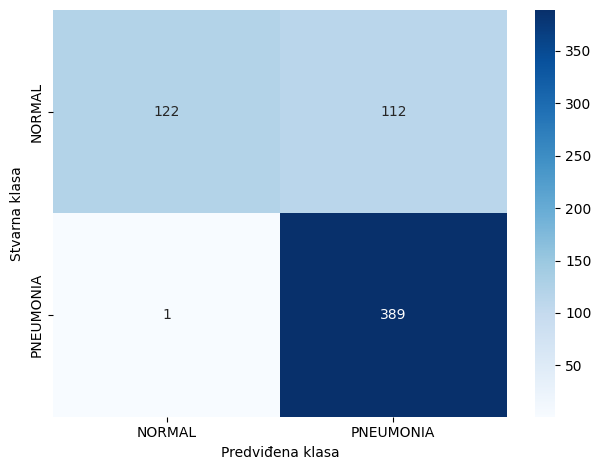

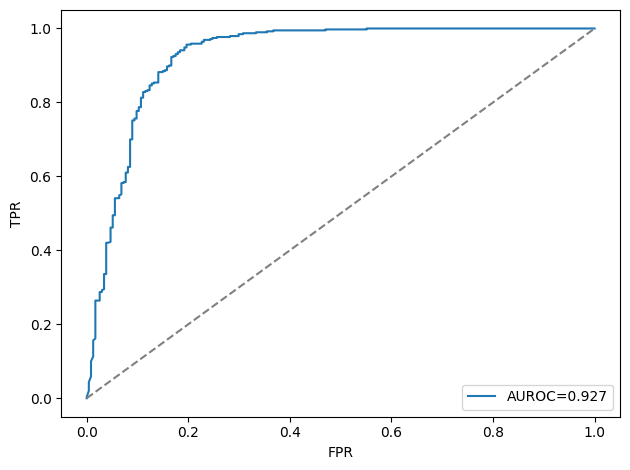

Analiza pogrešaka: {'TN': 122, 'FP': 112, 'FN': 1, 'TP': 389, 'specificity_normal': 0.5213675213675214, 'false_positive_rate': 0.47863247863247865, 'false_negative_rate': 0.002564102564102564}
Usporedba pragova na VALIDACIJI (nije optimizacija na testu):
 threshold  accuracy  precision_pneumonia  recall_pneumonia  f1_pneumonia  specificity_normal
       0.3     0.994                0.995             0.997         0.996               0.985
       0.4     0.995                0.997             0.997         0.997               0.990
       0.5     0.995                0.997             0.997         0.997               0.990
       0.6     0.994                0.997             0.995         0.996               0.990
       0.7     0.995                0.998             0.995         0.997               0.995


In [6]:
# Sigurnosna provjera: evaluacija se smije izvršiti samo s treniranim modelom.
checkpoint_path = OUT / 'resnet18_best.pt'
if not checkpoint_path.is_file():
    raise FileNotFoundError('Nedostaje trenirani model. Pokreni sve prethodne ćelije redom, uključujući treniranje (odjeljak 4).')
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint['state_dict'], strict=True)
model.to(device).eval()
assert checkpoint['classes'] == CLASSES, 'Klase spremljenog modela ne odgovaraju podacima.'
print('Evaluacija: uspješno učitan TRENIRANI model:', checkpoint_path)

ys = []
preds = []
probs = []

with torch.no_grad():
    for x, y in loaders['test']:
        logits = model(x.to(device))
        p = logits.softmax(1)[:, 1].cpu().numpy()
        ys.extend(y.numpy().tolist())
        probs.extend(p.tolist())
        preds.extend((p >= 0.5).astype(int).tolist())

ys = np.array(ys)
preds = np.array(preds)
probs = np.array(probs)

pr, rc, f1, _ = precision_recall_fscore_support(ys, preds, average='binary', zero_division=0)
metrics = {
    'accuracy': accuracy_score(ys, preds),
    'precision_pneumonia': pr,
    'recall_pneumonia': rc,
    'f1_pneumonia': f1,
    'auroc': roc_auc_score(ys, probs)
}

print(pd.Series(metrics).round(4))
print(classification_report(ys, preds, target_names=CLASSES, zero_division=0))
pd.DataFrame([metrics]).to_csv(OUT/'metrike.csv', index=False)

cm = confusion_matrix(ys, preds, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASSES, yticklabels=CLASSES, cmap='Blues')
plt.xlabel('Predviđena klasa')
plt.ylabel('Stvarna klasa')
plt.tight_layout()
plt.savefig(OUT/'matrica_zabune.png', dpi=170)
plt.show()

fpr, tpr, _ = roc_curve(ys, probs)
plt.plot(fpr, tpr, label=f'AUROC={metrics["auroc"]:.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.tight_layout()
plt.savefig(OUT/'roc.png', dpi=170)
plt.show()

pd.DataFrame({'path': [x for x, _ in test_items], 'true': ys, 'pred': preds, 'p_pneumonia': probs}).to_csv(OUT/'test_predikcije.csv', index=False)
# Detaljna analiza pogrešaka (prag 0,5): oba tipa pogrešaka i specifičnost.
tn,fp,fn,tp=cm.ravel()
error_analysis={'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
                'specificity_normal':float(tn/(tn+fp)) if tn+fp else None,
                'false_positive_rate':float(fp/(fp+tn)) if fp+tn else None,
                'false_negative_rate':float(fn/(fn+tp)) if fn+tp else None}
print('Analiza pogrešaka:',error_analysis)
pd.DataFrame([error_analysis]).to_csv(OUT/'analiza_pogresaka.csv',index=False)

# Pragove istražujemo ISKLJUČIVO na validacijskom skupu. Test ostaje na 0,5.
val_y=[];val_p=[]
with torch.no_grad():
    for x,y in loaders['val']:
        p=model(x.to(device)).softmax(1)[:,1].cpu().numpy()
        val_y.extend(y.numpy().tolist());val_p.extend(p.tolist())
val_y=np.asarray(val_y);val_p=np.asarray(val_p)
threshold_rows=[]
for threshold in [0.3,0.4,0.5,0.6,0.7]:
    pred_t=(val_p>=threshold).astype(int)
    precision_t,recall_t,f1_t,_=precision_recall_fscore_support(val_y,pred_t,average='binary',zero_division=0)
    cm_t=confusion_matrix(val_y,pred_t,labels=[0,1]);tn_t,fp_t,fn_t,tp_t=cm_t.ravel()
    threshold_rows.append({'threshold':threshold,'accuracy':accuracy_score(val_y,pred_t),
        'precision_pneumonia':precision_t,'recall_pneumonia':recall_t,'f1_pneumonia':f1_t,
        'specificity_normal':tn_t/(tn_t+fp_t) if tn_t+fp_t else np.nan})
threshold_df=pd.DataFrame(threshold_rows)
print('Usporedba pragova na VALIDACIJI (nije optimizacija na testu):')
print(threshold_df.round(3).to_string(index=False))
threshold_df.to_csv(OUT/'pragovi_validacija.csv',index=False)


## 6. XAI: Grad-CAM, Grad-CAM++ i Integrated Gradients
Sve metode objašnjavaju **predviđenu klasu** na istom ulazu. Za Grad-CAM metode koristi se posljednji konvolucijski blok (`layer4[-1]`). Za Integrated Gradients početna referenca je crna slika u nenormaliziranom RGB prostoru, zatim normalizirana istom transformacijom. Integrated Gradients prikazuje predznačene atribucije (crveno povećava, plavo smanjuje rezultat za predviđenu klasu); boje su relativno skalirane za svaku sliku. Vizualizacije su **relativne atribucije**, ne dokazi patološke lokalizacije.

Odabrani primjeri: [('TP', 473), ('TN', 227), ('FP', 213), ('FN', 348)]


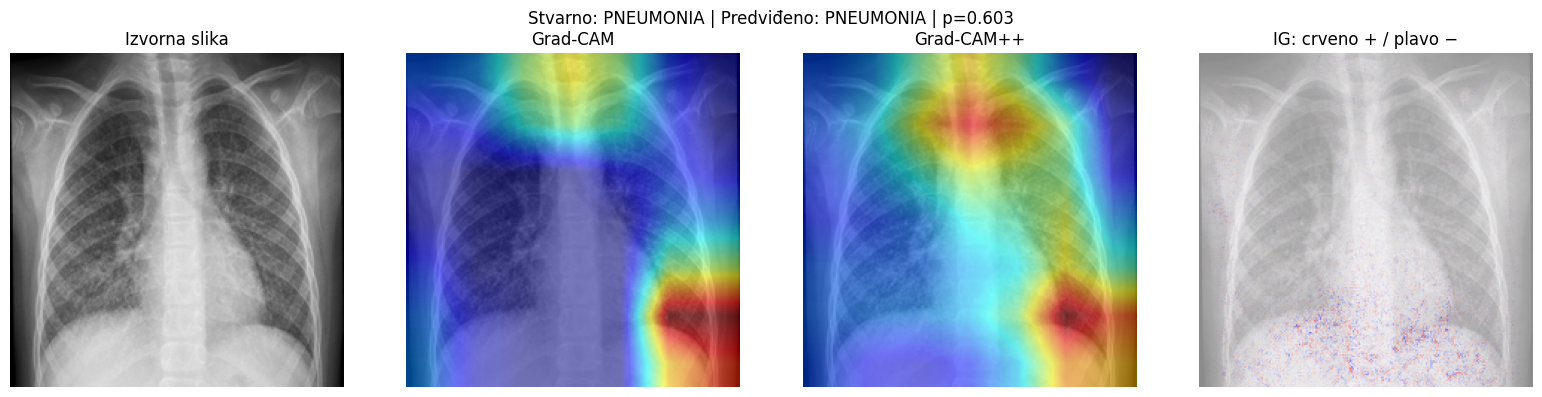

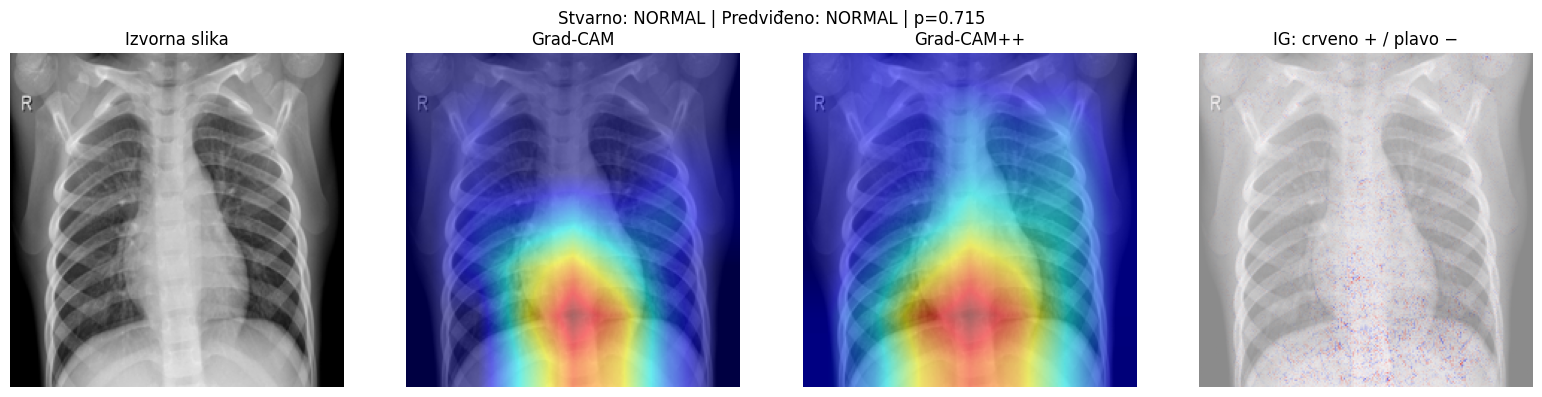

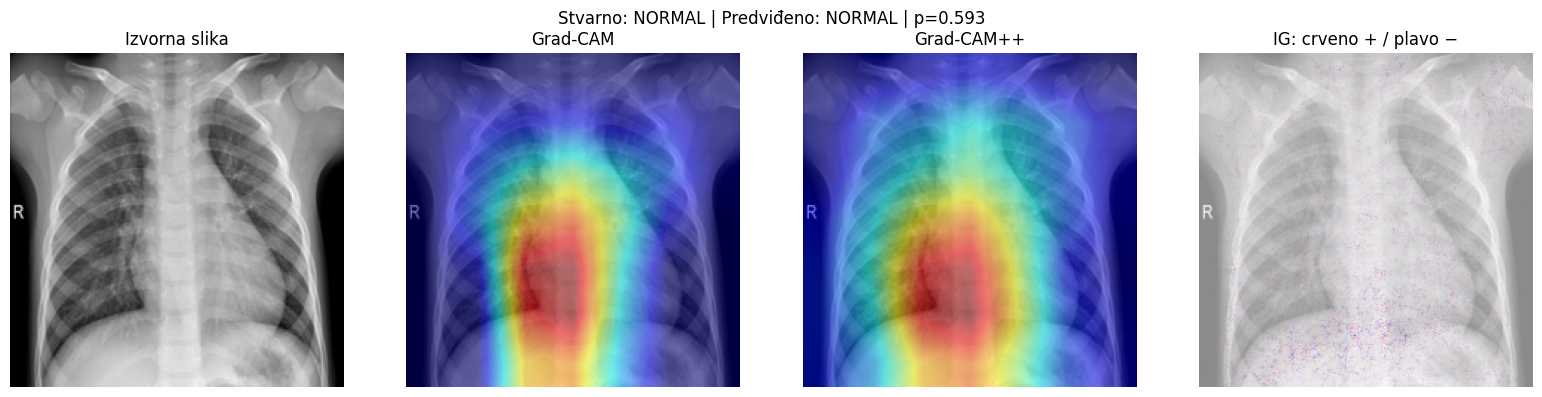

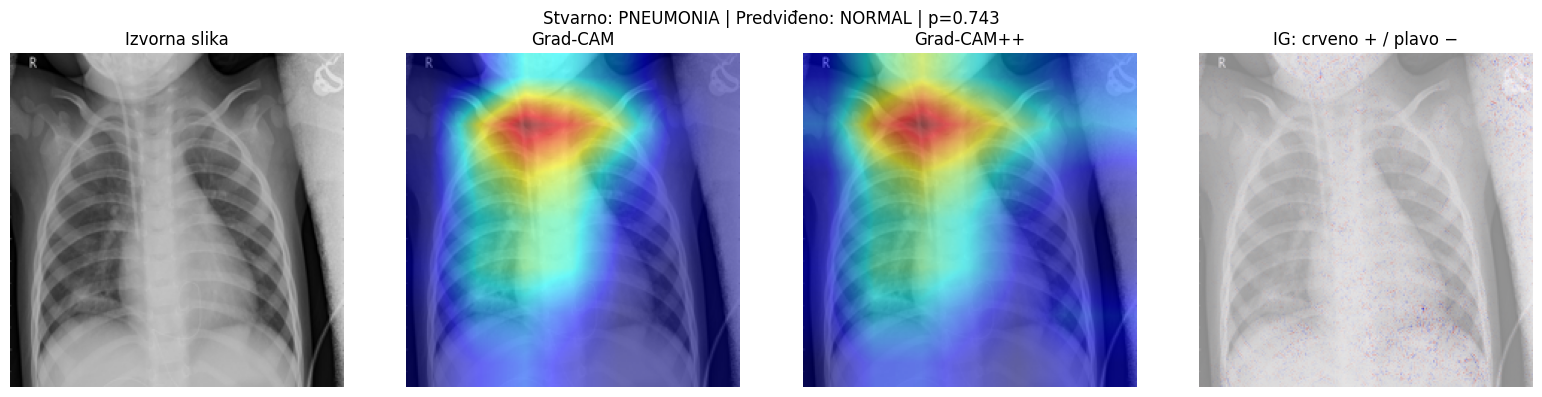

In [7]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients

# XAI se izvršava tek nakon evaluacije istog treniranog modela.
assert 'ys' in globals() and 'preds' in globals(), 'Najprije pokreni evaluaciju (odjeljak 5).'
assert (OUT / 'resnet18_best.pt').is_file(), 'Nedostaje trenirani model.'
model.eval()

def explain_one(index,save=True):
 path,true=test_items[index]
 with Image.open(path) as im: raw=np.asarray(im.convert('RGB').resize((SIZE,SIZE)),dtype=np.float32)/255.0
 x=eval_tf(Image.fromarray((raw*255).astype('uint8'))).unsqueeze(0).to(device)
 model.eval()
 with torch.no_grad(): predicted=int(model(x).argmax(1).item());confidence=float(model(x).softmax(1)[0,predicted].item())
 targets=[ClassifierOutputTarget(predicted)]
 with GradCAM(model=model,target_layers=[model.layer4[-1]]) as cam:
  gc=cam(input_tensor=x,targets=targets)[0]
 with GradCAMPlusPlus(model=model,target_layers=[model.layer4[-1]]) as cam:
  gcpp=cam(input_tensor=x,targets=targets)[0]
 baseline=transforms.Normalize(MEAN,STD)(torch.zeros_like(x[0]).cpu()).unsqueeze(0).to(device)
 ig=IntegratedGradients(model)
 attr=ig.attribute(x,baselines=baseline,target=predicted,n_steps=32,internal_batch_size=8)
 # apsolutna atribucija, agregirana po kanalima
 # Predznačene atribucije: pozitivno (crveno) i negativno (plavo).
 heat=attr.detach().sum(dim=1)[0].cpu().numpy()
 scale=np.max(np.abs(heat))+1e-8
 heat=heat/scale
 fig,ax=plt.subplots(1,4,figsize=(16,4))
 ax[0].imshow(raw);ax[0].set_title('Izvorna slika')
 ax[1].imshow(show_cam_on_image(raw,gc,use_rgb=True));ax[1].set_title('Grad-CAM')
 ax[2].imshow(show_cam_on_image(raw,gcpp,use_rgb=True));ax[2].set_title('Grad-CAM++')
 ax[3].imshow(raw);ax[3].imshow(heat,cmap='bwr',alpha=0.55,vmin=-1,vmax=1);ax[3].set_title('IG: crveno + / plavo −')
 for a in ax:a.axis('off')
 fig.suptitle(f'Stvarno: {CLASSES[true]} | Predviđeno: {CLASSES[predicted]} | p={confidence:.3f}')
 plt.tight_layout()
 if save:fig.savefig(OUT/f'xai_test_{index}.png',dpi=180,bbox_inches='tight')
 plt.show();plt.close(fig)
 return {'index':index,'path':path,'true':CLASSES[true],'predicted':CLASSES[predicted],'confidence':confidence}

# Reprezentativni primjeri: TP, TN, FP i FN, ako su dostupni.
# Odabir je deterministički (najbliži vjerojatnosti 0,5 unutar skupine).
categories={'TP':np.flatnonzero((ys==1)&(preds==1)),
            'TN':np.flatnonzero((ys==0)&(preds==0)),
            'FP':np.flatnonzero((ys==0)&(preds==1)),
            'FN':np.flatnonzero((ys==1)&(preds==0))}
selected=[];labels=[]
for label,indices in categories.items():
    if len(indices):
        idx=int(indices[np.argmin(np.abs(probs[indices]-0.5))])
        selected.append(idx);labels.append(label)
    else:
        print(f'Nema primjera kategorije {label} u testnom skupu.')
print('Odabrani primjeri:',list(zip(labels,selected)))
examples=[]
for label,idx in zip(labels,selected):
    result=explain_one(idx);result['error_type']=label;examples.append(result)
pd.DataFrame(examples).to_csv(OUT/'xai_primjeri.csv',index=False)


## 7. Analiza i izvoz
Za svaku mapu provjerite: (1) jesu li istaknuta plućna polja ili rubovi/oznake, (2) jesu li tri metode suglasne, (3) postoje li lažno pozitivni i lažno negativni primjeri. Bez anotacija radiologa nije moguće objektivno potvrditi kliničku lokalizaciju. Unesite **vlastita opažanja** u Word rad. ZIP preuzmite iz Colaba.
U `analiza_pogresaka.csv` nalazi se specifičnost i broj FP/FN slučajeva; `pragovi_validacija.csv` prikazuje kako se metrike mijenjaju na validacijskom skupu. Odabrane XAI slike obuhvaćaju TP/TN/FP/FN kada takvi primjeri postoje. Kvalitativna interpretacija slika ostaje dio pisanog seminarskog rada.


In [8]:
import json
import shutil
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

assert 'metrics' in globals() and 'examples' in globals(), 'Najprije pokreni evaluaciju i XAI ćelije.'

summary={
    'dataset':'Chest X-Ray Images (Pneumonia), Kaggle paultimothymooney',
    'model':'ResNet18',
    'seed':SEED,
    'epochs':EPOCHS,
    'split':{'train':len(train_items),'val':len(val_items),'test':len(test_items)},
    'metrics':metrics,
    'error_analysis':error_analysis,
    'threshold_analysis':'pragovi_validacija.csv (isključivo validacija; testni prag 0.5)',
    'experiment_info':experiment_info,
    'limitations':[
        'Nije potvrđena neovisnost pacijenata',
        'Nema radioloških anotacija za lokalizacijsku validaciju',
        'Jedan skup podataka; nije provjerena vanjska generalizacija'
    ]
}

(OUT/'sazetak.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
zip_base = str(OUT.parent / 'XAI_Rendgenske_snimke_rezultati')
shutil.make_archive(zip_base,'zip',OUT)
print('ZIP trajno spremljen:', zip_base + '.zip')

from google.colab import files
# Po želji preuzmi ZIP na računalo:
# files.download(zip_base + '.zip')

ZIP trajno spremljen: /content/drive/MyDrive/XAI_Rendgenske_snimke_rezultati.zip
